In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

In [31]:
df_diario = pd.read_parquet("../data/processed/datos_meteo_Valencia_91-25(days).parquet")
df_mensual = pd.read_parquet("../data/processed/datos_meteo_Valencia_91-25(month).parquet")
df_mensual.info()

<class 'pandas.DataFrame'>
PeriodIndex: 420 entries, 1991-01 to 2025-12
Freq: M
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   temp_med_mar (Cº)      420 non-null    float64
 1   temp_med_mes (Cº)      420 non-null    float64
 2   temp_med_max (Cº)      420 non-null    float64
 3   temp_med_min (Cº)      420 non-null    float64
 4   temp_abs_max (Cº)      420 non-null    float64
 5   temp_abs_min (Cº)      420 non-null    float64
 6   dias_temp>30           420 non-null    int64  
 7   total_precip_mes (mm)  420 non-null    float64
 8   precip_max (mm)        420 non-null    float64
 9   dias_precip>10mm       420 non-null    Int64  
 10  dias_precip>30mm       420 non-null    Int64  
 11  dias_lluvia            420 non-null    int64  
 12  dias_granizo           420 non-null    int64  
 13  dias_tormenta          420 non-null    int64  
 14  humedad_med (%)        420 non-null    float64
 15

¡Gráfico corregido guardado con éxito como 'matriz_quinquenal_con_valores_corregida.png'!


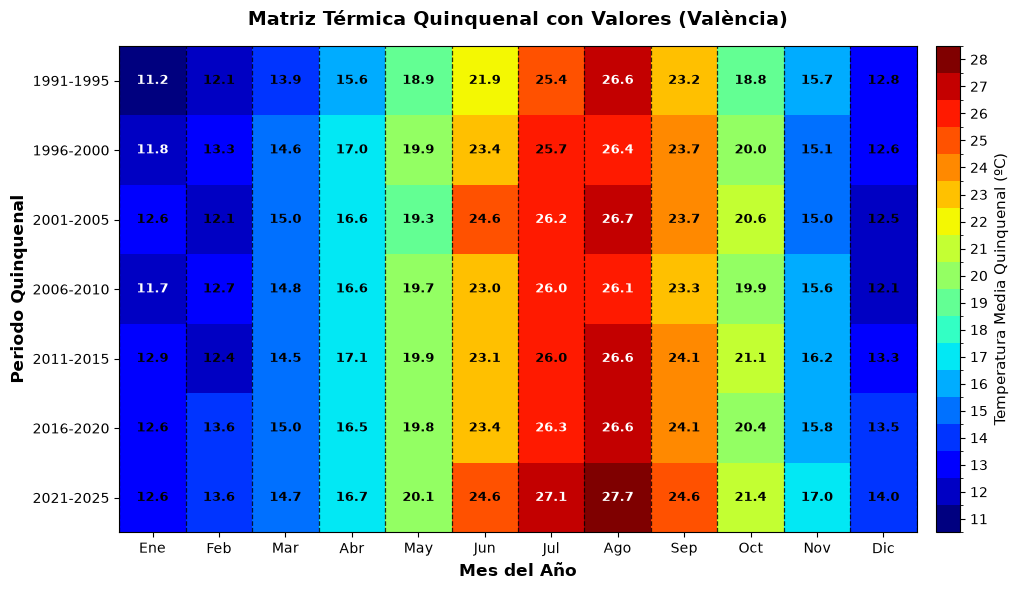

In [ ]:
# 1. Preparar los datos y agrupar en bloques de 5 años y por meses
df_plot = df_diario.copy()
if 'anio' not in df_plot.columns:
    df_plot['anio'] = df_plot.index.year
df_plot['mes'] = df_plot.index.month

# Definir los intervalos de 5 años (quinquenios)
bins = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025]
labels = ['1991-1995', '1996-2000', '2001-2005', '2006-2010', '2011-2015', '2016-2020', '2021-2025']
df_plot['periodo'] = pd.cut(df_plot['anio'], bins=bins, labels=labels)

# Crear tabla pivote: Filas = Periodos quinquenales, Columnas = Meses (1-12)
df_5years = df_plot.groupby(['periodo', 'mes'])['tmed'].mean().unstack(level=1)

# 2. Definir límites semi-enteros para evitar que los números enteros caigan en las fronteras
min_t = np.floor(df_5years.min().min())
max_t = np.ceil(df_5years.max().max())
boundaries = np.arange(min_t - 0.5, max_t + 1.5, 1.0)  # Ej: ... 25.5, 26.5, 27.5 ...

# Crear un mapa de colores discreto basado en 'jet'
cmap = plt.get_cmap('jet', len(boundaries) - 1)
norm = BoundaryNorm(boundaries, cmap.N, clip=True)

# 3. Configurar la figura estática
fig, ax = plt.subplots(figsize=(11, 6))

# imshow con los límites discretos corregidos
im = ax.imshow(
    df_5years.values, 
    aspect='auto', 
    cmap=cmap, 
    norm=norm,
    interpolation='nearest'
)

# Añadir barra de colores con marcas en los valores enteros reales
ticks_enteros = np.arange(int(min_t), int(max_t) + 1)
cbar = plt.colorbar(im, ax=ax, ticks=ticks_enteros, pad=0.02)
cbar.set_label('Temperatura Media Quinquenal (ºC)', fontsize=11)

# 4. Escribir el valor numérico de la temperatura en cada celda
matriz_valores = df_5years.values
for i in range(matriz_valores.shape[0]):
    for j in range(matriz_valores.shape[1]):
        val = matriz_valores[i, j]
        if not np.isnan(val):
            # Contraste de texto inteligente según el valor térmico
            color_texto = 'white' if val < 12 or val > 26 else 'black'
            ax.text(j, i, f"{val:.1f}", ha='center', va='center', color=color_texto, fontsize=9, fontweight='bold')

# 5. Configurar el eje X (Meses) y dibujar líneas verticales negras entre los meses
meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

for i in range(len(meses_nombres) + 1):
    ax.axvline(x=i - 0.5, color='black', linestyle='--', linewidth=0.9, alpha=0.8)

ax.set_xticks(range(len(meses_nombres)))
ax.set_xticklabels(meses_nombres, fontsize=10)
ax.set_xlabel('Mes del Año', fontsize=12, fontweight='bold')

# 6. Configurar el eje Y (Periodos: 1991-1995 arriba, 2021-2025 abajo)
periodos = df_5years.index.astype(str)
ax.set_yticks(range(len(periodos)))
ax.set_yticklabels(periodos, fontsize=10)
ax.set_ylabel('Periodo Quinquenal', fontsize=12, fontweight='bold')

# 7. Estética final y guardado
ax.set_title('Matriz Térmica Quinquenal con Valores (València)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()

# Guardar en alta calidad para el documento del TFM
archivo_imagen = "matriz_quinquenal_con_valores_corregida.png"
plt.savefig(archivo_imagen, dpi=300, bbox_inches='tight')
print(f"¡Gráfico corregido guardado con éxito como '{archivo_imagen}'!")

plt.show()

¡Gráfico de la temperatura del agua guardado con éxito como 'matriz_agua_quinquenal_con_valores.png'!


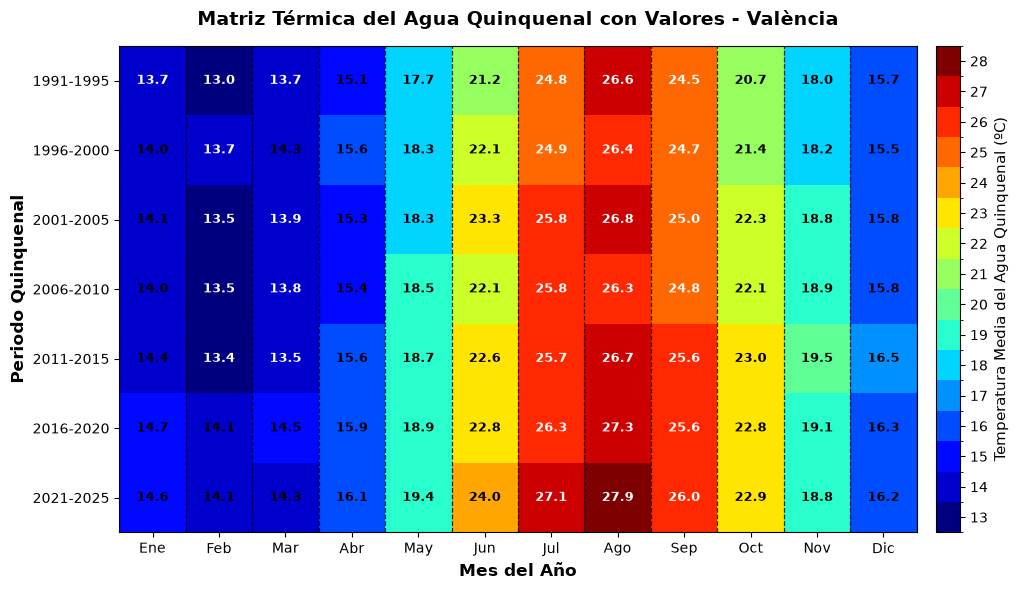

In [33]:
columna_agua = 'temp_med_mar (Cº)' 

# 1. Preparar los datos y agrupar en bloques de 5 años y por meses
df_plot = df_mensual.copy()
if 'anio' not in df_plot.columns:
    df_plot['anio'] = df_plot.index.year
df_plot['mes'] = df_plot.index.month

# Definir los intervalos de 5 años (quinquenios)
bins = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025]
labels = ['1991-1995', '1996-2000', '2001-2005', '2006-2010', '2011-2015', '2016-2020', '2021-2025']
df_plot['periodo'] = pd.cut(df_plot['anio'], bins=bins, labels=labels)

# Crear tabla pivote: Filas = Periodos quinquenales, Columnas = Meses (1-12)
df_5years = df_plot.groupby(['periodo', 'mes'])[columna_agua].mean().unstack(level=1)

# 2. Definir límites semi-enteros basados en los datos del agua (intervalos de 1 ºC)
min_t = np.floor(df_5years.min().min())
max_t = np.ceil(df_5years.max().max())
boundaries = np.arange(min_t - 0.5, max_t + 1.5, 1.0)

# Crear un mapa de colores discreto basado en 'jet'
cmap = plt.get_cmap('jet', len(boundaries) - 1)
norm = BoundaryNorm(boundaries, cmap.N, clip=True)

# 3. Configurar la figura estática
fig, ax = plt.subplots(figsize=(11, 6))

# imshow con los límites discretos corregidos
im = ax.imshow(
    df_5years.values, 
    aspect='auto', 
    cmap=cmap, 
    norm=norm,
    interpolation='nearest'
)

# Añadir barra de colores con marcas en los valores enteros reales
ticks_enteros = np.arange(int(min_t), int(max_t) + 1)
cbar = plt.colorbar(im, ax=ax, ticks=ticks_enteros, pad=0.02)
cbar.set_label('Temperatura Media del Agua Quinquenal (ºC)', fontsize=11)

# 4. Escribir el valor numérico exacto de la temperatura en cada celda
matriz_valores = df_5years.values
for i in range(matriz_valores.shape[0]):
    for j in range(matriz_valores.shape[1]):
        val = matriz_valores[i, j]
        if not np.isnan(val):
            # Contraste de texto inteligente según el valor térmico del agua
            color_texto = 'white' if val < 14 or val > 24 else 'black'
            ax.text(j, i, f"{val:.1f}", ha='center', va='center', color=color_texto, fontsize=9, fontweight='bold')

# 5. Configurar el eje X (Meses) y dibujar líneas verticales negras entre los meses
meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

for i in range(len(meses_nombres) + 1):
    ax.axvline(x=i - 0.5, color='black', linestyle='--', linewidth=0.9, alpha=0.8)

ax.set_xticks(range(len(meses_nombres)))
ax.set_xticklabels(meses_nombres, fontsize=10)
ax.set_xlabel('Mes del Año', fontsize=12, fontweight='bold')

# 6. Configurar el eje Y (Periodos: 1991-1995 arriba, 2021-2025 abajo)
periodos = df_5years.index.astype(str)
ax.set_yticks(range(len(periodos)))
ax.set_yticklabels(periodos, fontsize=10)
ax.set_ylabel('Periodo Quinquenal', fontsize=12, fontweight='bold')

# 7. Estética final y guardado
ax.set_title('Matriz Térmica del Agua Quinquenal con Valores - València', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()

# Guardar en alta calidad para el documento del TFM
archivo_imagen = "matriz_agua_quinquenal_con_valores.png"
plt.savefig(archivo_imagen, dpi=300, bbox_inches='tight')
print(f"¡Gráfico de la temperatura del agua guardado con éxito como '{archivo_imagen}'!")

plt.show()